# Homework 10


**Concepts covered:**

pandas `DataFrame`s: initialization,  descriptive statistics, line plot, scatter plot, histogram, column-wise operations, row-wise operations.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.

**Sample Output:**

For each problem description, a sample output has been included to show what the expected output should be.
Some functions have test cases provided for you to test with, so no sample output has been included for those.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [1]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.close("all")

# access to data file(s); update to week-10
df_stock_prices = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-10/SPY.csv")
df_stock_prices.index = pd.to_datetime(df_stock_prices["date"], unit='s')

df_weather = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-10/02215_weather.csv")
df_weather.index = pd.to_datetime(df_weather["datetime"], format="%m/%d/%y")


df_econ_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-10/annual_data.csv")
df_econ_data.index = df_econ_data["Year"]



**Note: This will be partially manually graded, so please allow some time before getting your full grade.**

**Review Problem 1**

**Concept:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that produces a spiral/cyclone pattern.

* Generate radius values that gradually increase
* Generate angle values that rotate around the origin
* Compute:
  * x = radius × cos(angle)
  * y = radius × sin(angle)
* Plot the points using plt.scatter()
* Add a title

(np.float64(-9.694340444723318),
 np.float64(10.937825735463015),
 np.float64(-10.257741779608363),
 np.float64(9.00875745827767))

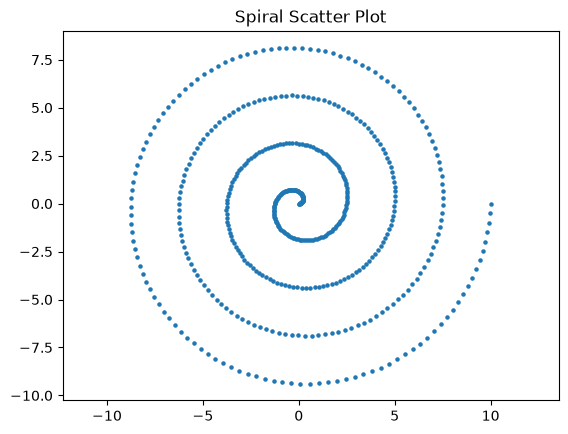

In [3]:
# Your Solution

radius = np.linspace(0, 10, 500)
angle = np.linspace(0, 8 * np.pi, 500)

# Convert polar coordinates to x and y coordinates.
x = radius * np.cos(angle)
y = radius * np.sin(angle)

plt.scatter(x, y, s=5)
plt.title("Spiral Scatter Plot")
plt.axis("equal")


**Review Problem 2**

**Concept:** *reading CSV data, matplotlib, line graph*

**Task:**

Write a function `read_and_plot_column(filename, column_name)` that:
* Opens a CSV file (do **not** use pandas)
* Extracts the values from the specified column
* Casts all values to `float`
* Plots the values using `plt.plot()`
* Adds a title
* Displays the plot

In [4]:
# Your Solution

def read_and_plot_column(filename, column_name):
    """Read a CSV column and display it as a line plot."""
    with open(filename, encoding="utf-8", newline="") as file:
        # Read the header and find the requested column.
        headers = np.loadtxt(file, delimiter=",", dtype=str, max_rows=1, quotechar='"')
        column_index = list(headers).index(column_name)

        # Read the remaining rows from that column as floats.
        values = np.loadtxt(file, delimiter=",", usecols=column_index, dtype=float, quotechar='"')

    plt.plot(values)
    plt.title(column_name)
    plt.show()

Test case for problem 2

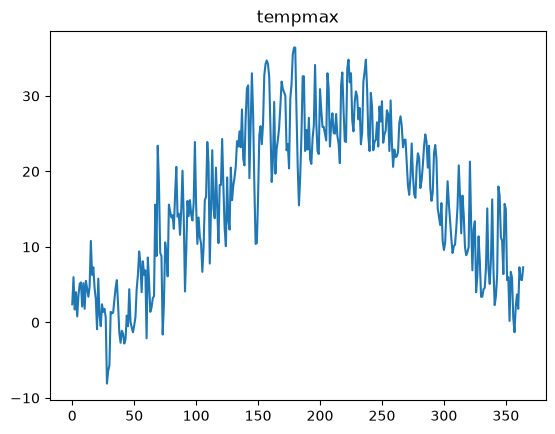

In [6]:
# test case:
read_and_plot_column("02215_weather.csv", "tempmax")


**Problem 3**

**Concept:** *Examining Data*


**Task:**

Using `df_weather`:
* Print the first 5 rows
* Print the last 5 rows

**Important:**

Store your results in the variables below and print them. The autograder will check for these variables.
* `df_weather_head`
* `df_weather_tail`

**Sample Output:**

If the following was your dataframe:

```
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50

```

The following will be your output:

```
FIRST 5 ROWS:
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50

LAST 5 ROWS:
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```


In [21]:
# Your Solution

df_weather_head = df_weather.head(5)
df_weather_tail = df_weather.tail(5)


print("FIRST 5 ROWS:")
display(df_weather_head)

print("\nLAST 5 ROWS:")
df_weather_tail

FIRST 5 ROWS:


,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-01,1/1/21,2.4,-2.4,0.5,2.3,-6.8,-1.9,-5.4,65.0,0.897,...,4.8,3,NaN,2021-01-01T07:13:45,2021-01-01T16:22:48,0.53,"Snow, Rain, Partially cloudy",Partly cloudy throughout the day with late aft...,rain,"KOWD,AV085,72509854704,KBED,0518W,KBOS,7250901..."
2021-01-02,1/2/21,6.0,0.1,3.9,3.8,-5.1,-0.4,1.6,85.7,12.092,...,2.4,1,NaN,2021-01-02T07:13:48,2021-01-02T16:23:41,0.56,"Snow, Rain, Partially cloudy",Partly cloudy throughout the day with rain or ...,rain,"KOWD,AV085,72509854704,KBED,0518W,KBOS,7250901..."
2021-01-03,1/3/21,1.7,-1.4,0.1,-1.7,-5.7,-3.8,-3.0,79.7,0.794,...,1.5,1,NaN,2021-01-03T07:13:49,2021-01-03T16:24:36,0.60,"Snow, Rain, Partially cloudy",Partly cloudy throughout the day with rain or ...,snow,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."
2021-01-04,1/4/21,4.0,-0.6,1.0,-0.3,-5.7,-3.5,-2.3,78.9,0.000,...,4.3,3,NaN,2021-01-04T07:13:47,2021-01-04T16:25:33,0.65,Partially cloudy,Partly cloudy throughout the day.,snow,"KOWD,AV085,72509854704,KBED,0518W,KBOS,7250901..."
2021-01-05,1/5/21,0.8,-1.0,-0.3,-3.9,-6.1,-4.8,-2.7,83.1,0.267,...,2.6,1,NaN,2021-01-05T07:13:43,2021-01-05T16:26:31,0.70,"Snow, Rain, Overcast",Cloudy skies throughout the day with afternoon...,rain,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."



LAST 5 ROWS:


,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
datetime,,,,,,,,,,,,,,,,,,,,,
2021-12-27,12/27/21,1.8,-1.1,0.5,1.8,-6.3,-3.1,-5.1,65.9,0.000,...,3.2,2,NaN,2021-12-27T07:12:50,2021-12-27T16:18:37,0.78,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,0..."
2021-12-28,12/28/21,7.3,0.6,3.8,4.0,-1.2,1.7,-0.7,74.5,1.075,...,4.2,3,NaN,2021-12-28T07:13:06,2021-12-28T16:19:21,0.83,"Snow, Rain, Overcast",Cloudy skies throughout the day with rain or s...,rain,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."
2021-12-29,12/29/21,5.7,2.5,4.3,5.7,0.0,3.3,-1.0,69.5,0.055,...,2.9,2,NaN,2021-12-29T07:13:19,2021-12-29T16:20:07,0.88,"Rain, Overcast",Cloudy skies throughout the day with early mor...,rain,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."
2021-12-30,12/30/21,5.6,3.3,4.6,5.6,1.1,3.5,2.6,87.6,1.286,...,1.3,1,NaN,2021-12-30T07:13:30,2021-12-30T16:20:55,0.93,"Rain, Overcast",Cloudy skies throughout the day with rain.,rain,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."
2021-12-31,12/31/21,7.3,4.4,6.0,7.3,3.2,5.3,4.8,92.5,0.000,...,1.8,1,NaN,2021-12-31T07:13:38,2021-12-31T16:21:44,0.97,Overcast,Cloudy skies throughout the day.,cloudy,"KOWD,72509854704,KBED,0518W,KBOS,72509014739,7..."


**Problem 4**

**Concept:** *Accessing `DataFrame` columns*


**Task:**

Using `df_weather`:
* Print all column names
* Create a list of columns that contain the substring `"temp"`
* Create a new DataFrame using only those columns
* Print the result

**Important:**

Store your result in the variable below and print it. The autograder will check for this variable.
* `df_weather_temp_cols`

**Sample Output:**

If the following were your column names and dataframe:
```
Index(['product', 'color', 'price'], dtype='object')

   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```

And you selected the columns that matched your condition, the following could be your output:
```
Index(['product', 'color', 'price'], dtype='object')

   product  color
P1   shirt   blue
P2   pants  black
P3     hat    red
P4  jacket  green
P5   shoes  white
```



In [26]:
# Your Solution
# column names
print(df_weather.columns)

# Collect column names containing "temp".
temp_columns = [column for column in df_weather.columns if "temp" in column]

# Select those columns and print the resulting DataFrame.
df_weather_temp_cols = df_weather[temp_columns]
df_weather_temp_cols


Index(['datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax',
       'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob',
       'precipcover', 'preciptype', 'snow', 'snowdepth', 'windgust',
       'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise',
       'sunset', 'moonphase', 'conditions', 'description', 'icon', 'stations'],
      dtype='str')


,tempmax,tempmin,temp
datetime,,,
2021-01-01,2.4,-2.4,0.5
2021-01-02,6.0,0.1,3.9
2021-01-03,1.7,-1.4,0.1
2021-01-04,4.0,-0.6,1.0
2021-01-05,0.8,-1.0,-0.3
...,...,...,...
2021-12-27,1.8,-1.1,0.5
2021-12-28,7.3,0.6,3.8
2021-12-29,5.7,2.5,4.3


**Problem 5**

**Concept:** *Descriptive Statistics*


**Task:**

Using `df_weather`:

* Display descriptive statistics for all columns

**Important:**

Store your result in the variable below and print it. The autograder will check for this variable.
* `df_weather_descriptive_statistics`

**Sample Output:**

If the following was your dataframe:
```
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```
The following will be your output:
```
DESCRIPTIVE STATISTICS:
           price
count   5.000000
mean   36.000000
std    19.235384
min    15.000000
25%    20.000000
50%    35.000000
75%    50.000000
max    60.000000

```



In [29]:
# Your Solution
df_weather_descriptive_statistics = df_weather.describe()
print("DESCRIPTIVE STATISTICS:")
df_weather_descriptive_statistics


DESCRIPTIVE STATISTICS:


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,precipprob,...,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,moonphase
count,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,...,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,0.0,365.000000
mean,16.215616,8.451781,12.292055,15.490411,6.158904,10.823288,5.084384,64.213151,3.654545,44.657534,...,25.798904,203.615890,1015.813699,64.498082,14.677808,128.181096,11.062740,4.956164,NaN,0.507178
std,10.236355,9.420414,9.609977,11.918353,11.772183,11.611922,10.629004,15.479875,9.119694,49.782003,...,8.894244,103.839985,7.188829,25.233514,2.424786,76.667991,6.617744,2.383147,NaN,0.309059
min,-8.100000,-14.300000,-10.400000,-16.700000,-25.600000,-20.300000,-21.000000,26.000000,0.000000,0.000000,...,10.800000,2.000000,992.400000,0.800000,4.400000,8.100000,0.700000,0.000000,NaN,0.000000
25%,7.100000,0.500000,3.900000,5.300000,-4.100000,0.400000,-3.800000,54.400000,0.000000,0.000000,...,19.900000,106.200000,1011.100000,45.500000,14.800000,65.800000,5.700000,3.000000,NaN,0.250000
50%,16.600000,8.900000,12.300000,16.600000,6.700000,12.100000,4.900000,64.400000,0.000000,0.000000,...,24.000000,232.200000,1015.400000,65.300000,15.800000,115.100000,9.800000,5.000000,NaN,0.500000
75%,24.200000,17.100000,20.400000,24.200000,17.100000,20.400000,14.500000,76.300000,2.243000,100.000000,...,30.600000,289.700000,1020.700000,87.300000,16.000000,192.200000,16.600000,7.000000,NaN,0.760000
max,36.400000,26.200000,31.200000,40.600000,26.200000,34.500000,22.100000,95.100000,83.845000,100.000000,...,89.000000,359.400000,1036.000000,100.000000,16.000000,303.600000,26.200000,9.000000,NaN,1.000000


**Problem 6**

**Concept:** *plotting, line graphs (time series)*


**Task:**

Using `df_weather`:
* Plot the `tempmax` column
* Add a title
* Display the plot

<Axes: title={'center': 'Maximum Temperature'}, xlabel='datetime'>

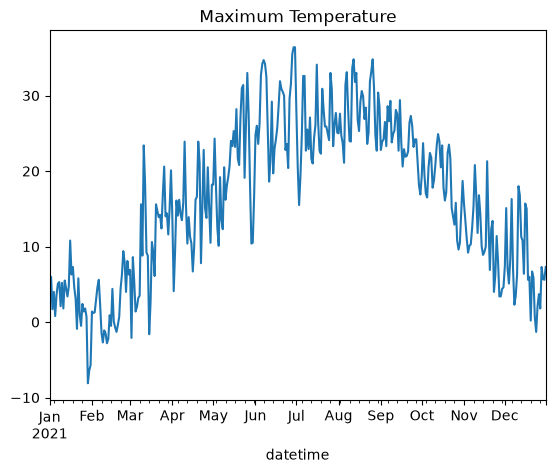

In [30]:
# Your Solution
df_weather["tempmax"].plot(title="Maximum Temperature")


**Problem 7**

**Concept:** *plotting, line graphs (time series)*


**Task:**

Using `df_weather`:
* Plot the `precip` column
* Add a title
* Display the plot


<Axes: title={'center': 'Precipitation'}, xlabel='datetime'>

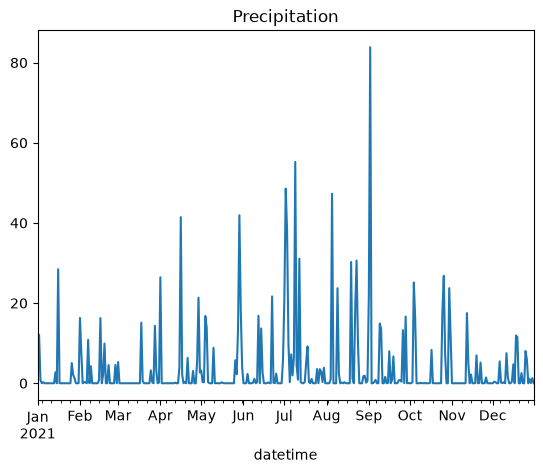

In [31]:
# Your Solution
df_weather["precip"].plot(title="Precipitation")



**Problem 8**

**Concept:** *histogram*


**Task:**

Using `df_weather`:
* Create a histogram of the `feelslike` column
* Use 25 bins
* Add a title
* Display the plot


Text(0.5, 1.0, 'Feels-Like Temperature Distribution')

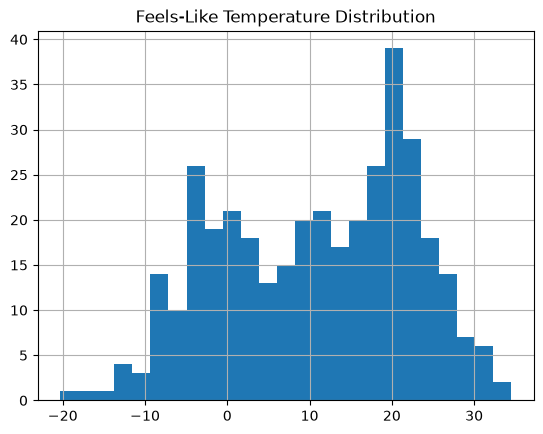

In [32]:
# Your Solution

df_weather["feelslike"].hist(bins=25)
plt.title("Feels-Like Temperature Distribution")


**Problem 9**

**Concept:** *pie chart*


**Task:**

* Print value counts of `df_weather['conditions']`
* Create a pie chart of the values
* Make sure to include labels
* Print value counts of `df_econ_data['PresidentParty']`
* Create a pie chart of the values
* Make sure to include labels

**Sample Output:**

If one of your columns contained the following values:
```
blue, black, red, green, white
```
The following could be your printed value counts:
```
blue     1
black    1
red      1
green    1
white    1
Name: color, dtype: int64
```
If another column contained the following values:
```
summer, winter, summer, spring, winter
```
The following could be your printed value counts:
```
summer    2
winter    2
spring    1
Name: season, dtype: int64
```

conditions
Partially cloudy                181
Rain, Partially cloudy           89
Rain, Overcast                   47
Snow, Rain, Overcast             18
Clear                            12
Overcast                          9
Snow, Rain, Partially cloudy      7
Snow, Overcast                    1
Snow, Partially cloudy            1
Name: count, dtype: int64

PresidentParty
Democrat      52
Republican    44
Name: count, dtype: int64

<Axes: title={'center': 'President Party'}>

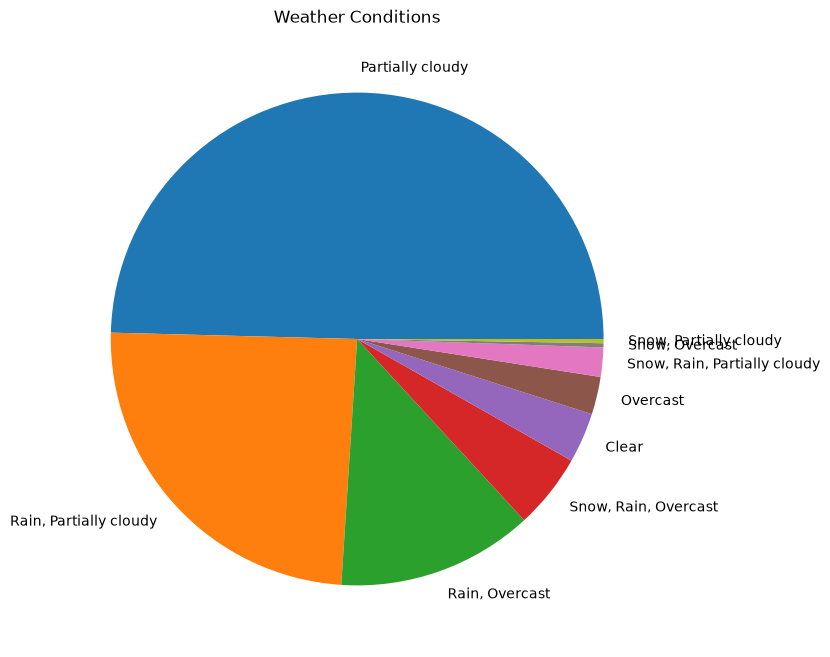

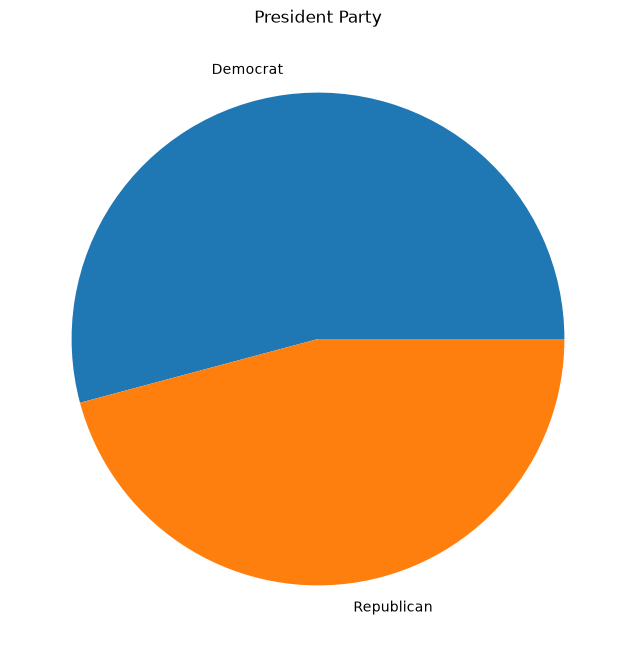

In [36]:
# Your Solution

# Count and plot weather conditions.
plt.figure(figsize=(8, 8))
conditions_counts = df_weather["conditions"].value_counts()
display(conditions_counts)
conditions_counts.plot.pie(title="Weather Conditions")


# Count and plot presidential parties.
plt.figure(figsize=(8, 8))
party_counts = df_econ_data["PresidentParty"].value_counts()
display(party_counts)
party_counts.plot.pie(title="President Party")




**Problem 10**

**Concept:** *creating new column data, extracting columns, plotting*


**Task:**

Using `df_weather`:
* Write a helper function to extract time (in hours) from a datetime string and convert it to decimal hours (float)
* Convert time using:

    `hours + (minutes / 60) + (seconds / 3600)`
* Create a new DataFrame with the same index as `df_weather`
* Add the following columns:
  * `sunrise` (converted to float)
  * `sunset` (converted to float)
  * `tempmin` (copied directly from `df_weather`)
* Plot all columns together using `.plot()`


**Sample Output:**

This is similar to how your new dataframe should look before plotting:

```
   start_time  end_time  price
P1       8.25     17.50     20
P2       8.50     17.75     35
P3       9.00     18.00     15
P4       9.25     18.25     60
P5       9.50     18.50     50
```

<Axes: title={'center': 'Sunrise, Sunset, and Minimum Temperature'}, xlabel='datetime'>

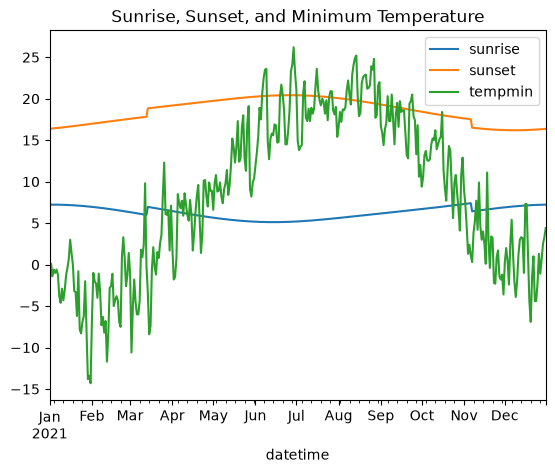

In [37]:
# Your Solution
def time_to_decimal(datetime_string):
    """Convert the time in a datetime string to decimal hours."""
    time = pd.to_datetime(datetime_string)
    return time.hour + time.minute / 60 + time.second / 3600


df_sun_temp = pd.DataFrame(index=df_weather.index)
df_sun_temp["sunrise"] = df_weather["sunrise"].apply(time_to_decimal)
df_sun_temp["sunset"] = df_weather["sunset"].apply(time_to_decimal)
df_sun_temp["tempmin"] = df_weather["tempmin"]

# Plot all three columns together.
df_sun_temp.plot(title="Sunrise, Sunset, and Minimum Temperature")



**Problem 11**

**Concept:** *descriptive statistics*


**Task:**


Using `df_stock_prices`:
* Print the first 5 rows
* Display descriptive statistics

**Important:**

Store your results in the variables below and print them. The autograder will check for these variables.
* `df_stock_prices_head`
* `df_stock_prices_descriptive_statistics`

**Sample Output:**


If the following was your dataframe:
```
   day  units_sold  revenue
1  Mon          10      200
2  Tue          15      300
3  Wed          12      240
4  Thu          18      360
5  Fri          20      400
```
The following will be your output:
```
SHOW FIRST 5 ROWS:
   day  units_sold  revenue
1  Mon          10      200
2  Tue          15      300
3  Wed          12      240
4  Thu          18      360
5  Fri          20      400

DESCRIPTIVE STATISTICS:
       units_sold     revenue
count    5.000000    5.000000
mean    15.000000  300.000000
std      4.123106   82.462113
min     10.000000  200.000000
25%     12.000000  240.000000
50%     15.000000  300.000000
75%     18.000000  360.000000
max     20.000000  400.000000
```

In [39]:
# Your Solution

# Store the first five rows and descriptive statistics.
df_stock_prices_head = df_stock_prices.head(5)
df_stock_prices_descriptive_statistics = df_stock_prices.describe()

print("SHOW FIRST 5 ROWS:")
display(df_stock_prices_head)

print("\nDESCRIPTIVE STATISTICS:")
display(df_stock_prices_descriptive_statistics)



SHOW FIRST 5 ROWS:


,formatted_date,date,high,low,open,close,volume,adjclose
date,,,,,,,,
2025-01-02 14:30:00,2025-01-02,1735828200,591.130005,580.500000,589.390015,584.640015,50204000,577.854126
2025-01-03 14:30:00,2025-01-03,1735914600,592.599976,586.429993,587.530029,591.950012,37888500,585.079285
2025-01-06 14:30:00,2025-01-06,1736173800,599.700012,593.599976,596.270020,595.359985,47679400,588.449707
2025-01-07 14:30:00,2025-01-07,1736260200,597.750000,586.780029,597.419983,588.630005,60393100,581.797791
2025-01-08 14:30:00,2025-01-08,1736346600,590.580017,585.200012,588.700012,589.489990,47304700,582.647766



DESCRIPTIVE STATISTICS:


,date,high,low,open,close,volume,adjclose
count,2.500000e+02,250.000000,250.000000,250.000000,250.000000,2.500000e+02,250.000000
mean,1.751600e+09,623.135160,616.066759,619.785518,619.962281,7.244500e+07,615.875577
std,9.049658e+06,45.091706,47.509124,46.521880,46.166514,2.913371e+07,47.576697
min,1.735828e+09,521.700012,481.799988,489.190002,496.480011,2.604870e+07,492.193634
25%,1.743709e+09,592.642487,585.069992,588.505005,589.415009,5.766440e+07,583.067184
50%,1.751722e+09,623.070007,617.959991,621.899994,620.565002,6.812535e+07,617.026031
75%,1.759390e+09,665.812515,659.307526,662.297516,662.537506,8.113838e+07,660.578079
max,1.767191e+09,691.659973,689.270020,690.640015,690.380005,2.566114e+08,690.380005


**Problem 12**

**Concept:** *line graph (time series)*


**Task:**

Using `df_stock_prices`:
* Plot the `adjclose` column
* Add a title
* Display the plot


<Axes: title={'center': 'Adjusted Closing Price'}, xlabel='date'>

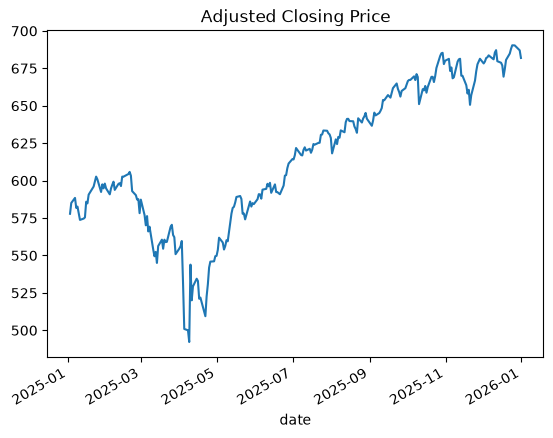

In [40]:
# Your Solution

df_stock_prices["adjclose"].plot(title="Adjusted Closing Price")



**Problem 13**

**Concept:** *histogram*


**Task:**

Using `df_stock_prices`:
* Create a histogram of `adjclose`
* Use 25 bins
* Add a title
* Display the plot


Text(0.5, 1.0, 'Adjusted Closing Price Distribution')

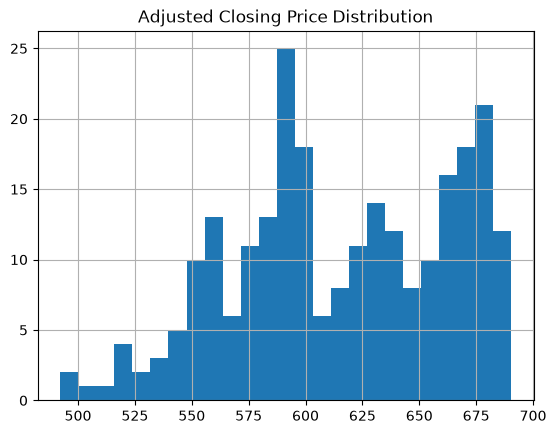

In [41]:
# Your Solution

# Plot the distribution of adjusted closing prices.
df_stock_prices["adjclose"].hist(bins=25)
plt.title("Adjusted Closing Price Distribution")


**Problem 14**

**Concept:** *Creating new column.*


**Task:**

Write a function `add_range_column(df, col_a, col_b)` that:
* Creates a new column `"range"` equal to `col_a - col_b`
* Returns the updated DataFrame

**Sample Output:**

If the following was your dataframe before adding the new column:
```
   price  discount
P1     20         2
P2     35         5
P3     15         1
P4     60        10
P5     50         8
```
The following will be your output after creating the `"range"` column:
```
   price  discount  range
P1     20         2     18
P2     35         5     30
P3     15         1     14
P4     60        10     50
P5     50         8     42
```

In [42]:
# Your Solution

def add_range_column(df, col_a, col_b):
    """Add the difference between two columns and return the DataFrame."""
    # Subtract the second column from the first, row by row.
    df["range"] = df[col_a] - df[col_b]
    return df

Test cases for problem 14

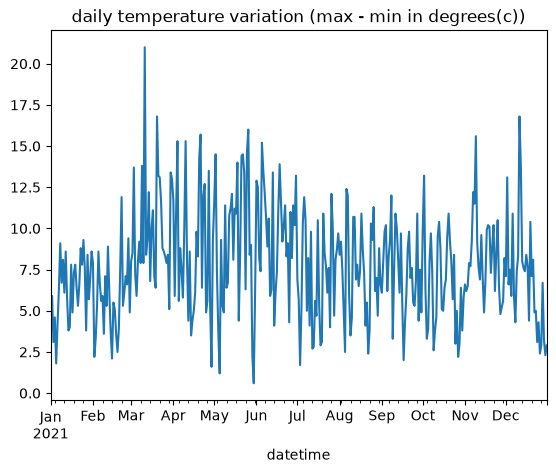

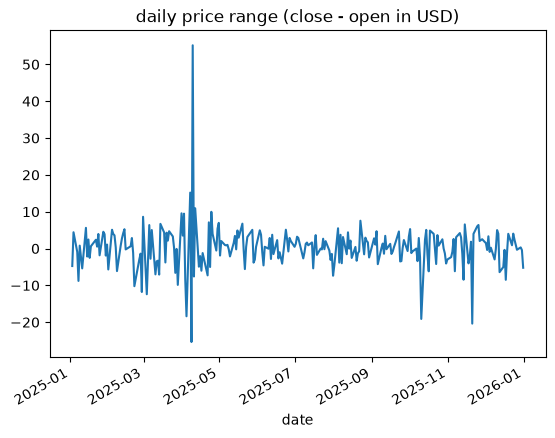

In [43]:
# test cases
df_result = add_range_column(df_weather, "tempmax", "tempmin")
df_result['range'].plot(title="daily temperature variation (max - min in degrees(c))")
plt.show()

df_result = add_range_column(df_stock_prices, "close", "open")
df_result['range'].plot(title="daily price range (close - open in USD)")
plt.show()




**Problem 15**

**Concept:** *Filtering `DataFrame` with boolean conditions*


**Task:**


Write a function `filter_rows_matching_pattern(df, column, pattern)` that:
* Returns rows where the specified column contains the given pattern
* Handles missing values
* Prints the number of matching rows

**Sample Output:**

If your selected column contained matching text values, the following could be your output:
```
Found 1 records of color containing blue.
Found 1 records of product containing hat.
Found 1 records of color containing red.
```

In [44]:
# Your Solution

def filter_rows_matching_pattern(df, column, pattern):
    """Return matching rows and print their count."""
    # Treat missing values as non-matches.
    matches = df[column].str.contains(pattern, na=False)
    result = df[matches]

    print(f"Found {len(result)} records of {column} containing {pattern}.")
    return result


Test cases for problem 15

In [45]:
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Snow")
# print(df_result.head())
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Overcast")
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Clear")
# print(df_result.head())


Found 27 records of conditions containing Snow.
Found 75 records of conditions containing Overcast.
Found 12 records of conditions containing Clear.


**Problem 16**

**Concept:** *Creating new DataFrame with categorical data.*


**Task:**

Write a function `create_df_categorical(df_source, column_name)` that:
* Creates a new DataFrame with:
  * counts of each category
  * percentage of each category
* Returns the new DataFrame

**Sample Output:**

If the following was one of your categorical columns:
```
blue, black, red, green, white
```
The following will be your output:
```
       count  pct
blue       1  0.2
black      1  0.2
red        1  0.2
green      1  0.2
white      1  0.2
```
If another categorical column contained:
```
summer, winter, summer, spring, winter
```
The following will be your output:
```
        count  pct
summer      2  0.4
winter      2  0.4
spring      1  0.2
```

In [46]:
# Your Solution
def create_df_categorical(df_source, column_name):
    """Return category counts and proportions."""
    # Count each category and calculate its share of non-missing values.
    counts = df_source[column_name].value_counts()
    result = pd.DataFrame({"count": counts, "pct": counts / counts.sum()})
    return result



Test cases for problem 16

In [47]:
# test cases:
# 1: show categories of conditions
df_result = create_df_categorical(df_weather, "conditions")
print("CONDITIONS:")
print(df_result)
# 2: show categories of description
df_result = create_df_categorical(df_weather, "description")
print("DESCRIPTION:")
print(df_result)
# 3: show categories of UV index
df_result = create_df_categorical(df_weather, "uvindex")
print("UV INDEX")
print(df_result)

CONDITIONS:
                              count       pct
conditions                                   
Partially cloudy                181  0.495890
Rain, Partially cloudy           89  0.243836
Rain, Overcast                   47  0.128767
Snow, Rain, Overcast             18  0.049315
Clear                            12  0.032877
Overcast                          9  0.024658
Snow, Rain, Partially cloudy      7  0.019178
Snow, Overcast                    1  0.002740
Snow, Partially cloudy            1  0.002740
DESCRIPTION:
                                                    count       pct
description                                                        
Partly cloudy throughout the day.                     154  0.421918
Partly cloudy throughout the day with late afte...     21  0.057534
Becoming cloudy in the afternoon.                      20  0.054795
Cloudy skies throughout the day with a chance o...     18  0.049315
Partly cloudy throughout the day with rain.            15  0.

**Problem 17**

**Concept:** *Filtering records by category.*


**Task:**

Write a function `filter_weather(df, conditions, temp_min, temp_max)` that:
* Filters rows where:
  * conditions contain the given string
  * `tempmax` ≤ `temp_max`
  * `tempmin` ≥ `temp_min`
* Prints intermediate counts
* Returns the filtered DataFrame

**Sample Output:**

If your data matched the filtering conditions step by step, the following could be your output:
```
4 records with conditions Blue
3 records with conditions Blue and tempmax <= 50
2 records with conditions Blue and 20 <= temp <= 50
Found 2 records with conditions of Blue and temp between 20 and 50.
```

In [48]:
# Your Solution

def filter_weather(df, conditions, temp_min, temp_max):
    """Filter weather records by conditions and temperature limits."""
    # Select matching conditions; missing values are not matches.
    result = df[df["conditions"].str.contains(conditions, na=False, regex=False)]
    print(f"{len(result)} records with conditions {conditions}")

    # Keep rows at or below the maximum temperature.
    result = result[result["tempmax"] <= temp_max]
    print(f"{len(result)} records with conditions {conditions} and tempmax <= {temp_max}")

    # Keep rows at or above the minimum temperature.
    result = result[result["tempmin"] >= temp_min]
    print(f"{len(result)} records with conditions {conditions} and {temp_min} <= temp <= {temp_max}")
    print(f"Found {len(result)} records with conditions of {conditions} and temp between {temp_min} and {temp_max}.")
    return result


Test cases for problem 17

In [49]:
# looking for perfect running days:
df_result = filter_weather(df_weather, "Partially cloudy", 4, 15)
print(f"The best running days were:")
print(df_result[['tempmin', 'tempmax','conditions',]])
print()

# looking for perfect beach days:
df_result = filter_weather(df_weather, "Clear", 5, 30)
print(f"The best beach days were:")
print(df_result[['tempmin', 'tempmax','conditions',]])



278 records with conditions Partially cloudy
110 records with conditions Partially cloudy and tempmax <= 15
19 records with conditions Partially cloudy and 4 <= temp <= 15
Found 19 records with conditions of Partially cloudy and temp between 4 and 15.
The best running days were:
            tempmin  tempmax              conditions
datetime                                            
2021-03-27      6.1     14.0        Partially cloudy
2021-03-29      6.5     11.6  Rain, Partially cloudy
2021-04-05      8.5     14.1        Partially cloudy
2021-04-07      6.8     14.3        Partially cloudy
2021-04-08      7.7     13.5        Partially cloudy
2021-04-13      5.3     13.9        Partially cloudy
2021-04-14      7.8     11.3        Partially cloudy
2021-04-26      8.2     13.8        Partially cloudy
2021-05-07      8.2     13.5        Partially cloudy
2021-05-08      7.4     12.3        Partially cloudy
2021-10-24      5.6     14.0        Partially cloudy
2021-10-28      6.6      9.6   

**Problem 18**

**Concept:** *Creating DataFrame, standardizing values.*


**Task:**

Write a function `create_standardized_values(df_source, columns, row_index=None)` that:
* Creates a new DataFrame
* Standardizes values relative to a given row
* Uses the first row if none is provided
* Returns the new DataFrame

**Sample Output:**

If the following was your dataframe:
```
      high_value  low_value
2020        100        50
2021        120        55
2022        140        60
2023        160        70
2024        180        75
```
If you call the function
`create_standardized_values(df_example, ["high_value", "low_value"], 2020)`,
you should get the following as the output:
```
      high_value  low_value
2020         1.0       1.00
2021         1.2       1.10
2022         1.4       1.20
2023         1.6       1.40
2024         1.8       1.50

```

In [50]:
# Your Solution
def create_standardized_values(df_source, columns, row_index=None):
    """Return selected columns divided by their values in a reference row."""
    selected = df_source[columns]

    # Use the first row unless a row label was provided.
    if row_index is None:
        reference = selected.iloc[0]
    else:
        reference = selected.loc[row_index]

    # Divide each column by its corresponding reference value.
    return selected / reference



Test cases for problem 18

<Axes: xlabel='Year'>

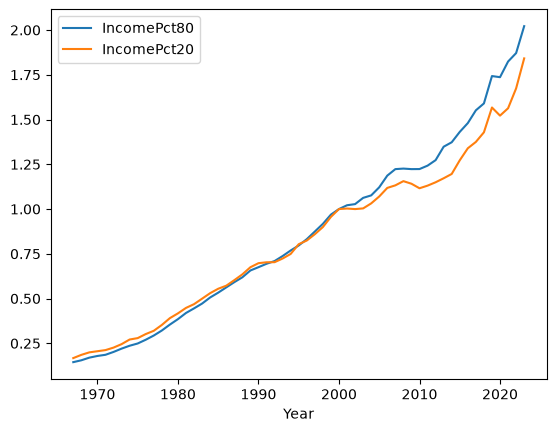

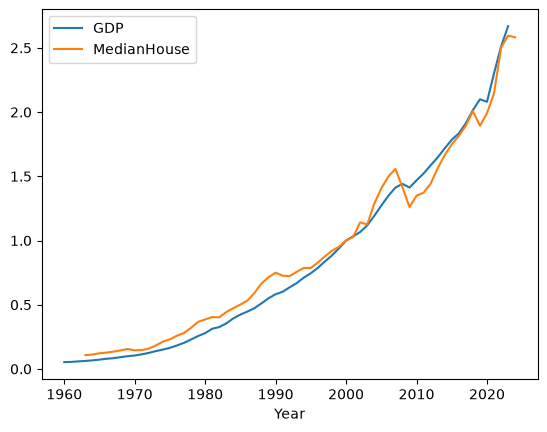

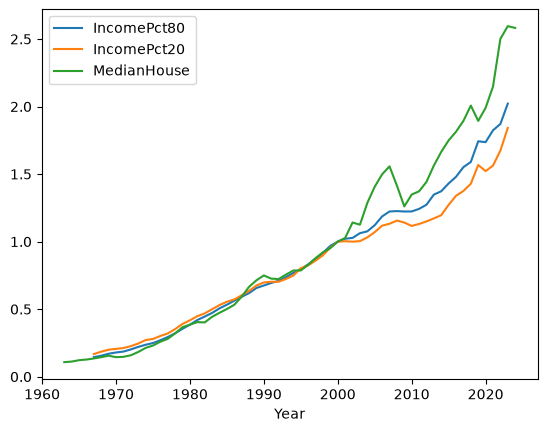

In [51]:
# test cases

# # show open/close prices relative to first item (row_index = None)
# df_result = create_standardized_values(df_stock_prices, ["open", "close"])
# df_result.plot()

# show values relative to year 2000
df_result = create_standardized_values(df_econ_data, ["IncomePct80", "IncomePct20"], 2000)
df_result.plot()

df_result = create_standardized_values(df_econ_data, ["GDP", "MedianHouse"], 2000)
df_result.plot()

df_result = create_standardized_values(df_econ_data, ["IncomePct80", "IncomePct20", "MedianHouse"], 2000)
df_result.plot()